In [2]:
import numpy as np
from numba import njit
import new_prisonersdilemma as pd
import matplotlib.pyplot as plt
from matplotlib.collections import LineCollection


ModuleNotFoundError: No module named 'new_prisonersdilemma'

In [ ]:
@njit
def compute_riemannian_gradients(gamma,UA,UB,eps):

    grad_A = np.zeros(3,dtype=np.float64)
    grad_B = np.zeros(3,dtype=np.float64)

    for k in range(3):

        direction = np.zeros(3,dtype=np.float64)
        direction[k]= eps

        UA_plus = UA @ pd.exp_su2(direction)
        UA_minus = UA @ pd.exp_su2(-direction)

        payoff_A_plus,_ = pd.compute_payoffs(gamma,UA_plus,UB,1)
        payoff_A_minus,_ = pd.compute_payoffs(gamma,UA_minus,UB,1)


        grad_A[k] = (payoff_A_plus - payoff_A_minus) / (2.0 * eps)

        UB_plus = UB @ pd.exp_su2(direction)
        UB_minus = UB @ pd.exp_su2(-direction)


        _, payoff_B_plus = pd.compute_payoffs(gamma,UA,UB_plus,1)
        _, payoff_B_minus = pd.compute_payoffs(gamma,UA,UB_minus,1)

        grad_B[k] = (payoff_B_plus - payoff_B_minus) / (2.0 * eps)

    # Gradient is represent by 3 coordinates in the su(2) tangent space
    return grad_A, grad_B



In [ ]:
@njit
def initialize_adam_state():
    m_A = np.zeros(3,dtype=np.float64)
    V_A = np.zeros((3,3),dtype=np.float64)

    m_B = np.zeros(3,dtype=np.float64)
    V_B = np.zeros((3,3),dtype=np.float64)

    return m_A, V_A, m_B, V_B



In [ ]:
@njit
def rotation_matrix(axis_angle):
    theta = np.sqrt(
        axis_angle[0] * axis_angle[0] + 
        axis_angle[1] * axis_angle[1] + 
        axis_angle[2] * axis_angle[2]  
    )

    R = np.eye(3,dtype=np.float64)

    if theta < 1e-15:
        return R

    kx = axis_angle[0] / theta
    ky = axis_angle[1] / theta
    kz = axis_angle[2] / theta

    c = np.cos(theta)
    s = np.sin(theta)

    one_minus_c = 1.0 - c

    R[0,0] = (
        c + kx * kx * one_minus_c
    )

    R[0, 1] = (
        kx * ky * one_minus_c - kz * s
    )

    R[0, 2] = (
        kx * kz * one_minus_c + ky * s
    )

    R[1,0]  = (
        ky * kx * one_minus_c + kz * s
    )

    R[1, 1] = (
        c + ky * ky * one_minus_c
    )

    R[1, 2] = (
        ky * kz * one_minus_c - kx * s
    )

    R[2 ,0] = (
        kz * kx * one_minus_c - ky * s
    )

    R[2, 1] = (
        kz * ky * one_minus_c + kx * s
    )

    R[2,2]= (
        c + kz * kz * one_minus_c
    )

    return R


In [ ]:
@njit
def vector_transport(v,delta):
    axis_angle = -0.5 * delta
    R = rotation_matrix(axis_angle)
    return R @ v

In [ ]:
@njit
def second_moment_transport(V,delta):
    axis_angle = - 0.5 * delta
    R = rotation_matrix(axis_angle)
    return R @ V @ R.T

In [ ]:
@njit
def adam_direction(m_hat,v_hat,eps):
    eigen_values,eigen_vectors = np.linalg.eigh(v_hat)

    result = np.zeros(3,dtype=np.float64)

    for i in range(3):
        value = eigen_values[i]

        if value < eps:
            value = eps
        inv_sqrt = 1.0 / np.sqrt(value)

        direction_component = 0.0

        for j in range(3):
            direction_component += (
                eigen_vectors[j,i] * m_hat[j]
            )

        direction_component *= inv_sqrt

        for j in range(3):
            result[j] += (eigen_vectors[j,i] * direction_component)
    return result

In [ ]:
@njit
def adam_update(grad, m, v, t, beta1, beta2, eps):

    for i in range(3):

        m[i]= (
            beta1 * m[i] + (1.0 - beta1) * grad[i]
        )

    for i in range(3):
        for j in range(3):
            v[i,j] = (
                beta2 * v[i,j] + (1.0 - beta2) * grad[i] * grad[j]
            )

    m_hat = np.zeros(3,dtype=np.float64)
    V_hat = np.zeros((3,3),dtype=np.float64)

    for k in range(3):
        m_hat[k] = (
            m[k] / (1.0 - beta1 ** t)
        )

    for i in range(3):
        for j in range(3):
            V_hat[i,j]= v[i,j] / (1.0 - beta2**t)
    direction = np.zeros(3,dtype=np.float64)
    direction = adam_direction(m_hat,V_hat,eps)

    return direction,m,v

In [ ]:
@njit

def riemannian_adam_step(gamma, UA, UB, m_A, V_A, m_B, V_B, t, learning_rate, beta1, beta2, adam_eps, grad_eps):
    grad_A, grad_B = compute_riemannian_gradients(gamma,UA,UB,grad_eps)

    d_A, m_A, V_A = adam_update(grad_A,m_A,V_A,t,beta1,beta2,adam_eps)

    d_B, m_B, V_B = adam_update(grad_B,m_B,V_B,t,beta1,beta2,adam_eps)

    delta_A = learning_rate * d_A
    delta_B = learning_rate * d_B

    
    UA = UA @ pd.exp_su2(delta_A)
    UB = UB @ pd.exp_su2(delta_B)

    # UA = pd.exp_su2(delta_A) @ UA  
    # UB = pd.exp_su2(delta_B) @ UB  


    m_A = vector_transport(m_A, delta_A)
    m_B = vector_transport(m_B, delta_B)
    V_A = second_moment_transport(V_A,delta_A)
    V_B = second_moment_transport(V_B,delta_B)
    return (
        UA,
        UB,
        m_A,
        V_A,
        m_B,
        V_B,
        grad_A,
        grad_B,
        delta_A,
        delta_B
    )


In [ ]:
@njit
def riemannian_adam_step_alternating(
    gamma,
    UA,
    UB,
    m_A,
    V_A,
    m_B,
    V_B,
    t,
    learning_rate,
    beta1,
    beta2,
    adam_eps,
    grad_eps
):

    # ============================================================
    # 1. Alice optimizes against Bob's CURRENT strategy
    # ============================================================

    grad_A, _ = compute_riemannian_gradients(
        gamma,
        UA,
        UB,
        grad_eps
    )

    d_A, m_A, V_A = adam_update(
        grad_A,
        m_A,
        V_A,
        t,
        beta1,
        beta2,
        adam_eps
    )

    delta_A = learning_rate * d_A

    UA = UA @ pd.exp_su2(delta_A)

    # Transport Alice's optimizer state
    m_A = vector_transport(
        m_A,
        delta_A
    )

    V_A = second_moment_transport(
        V_A,
        delta_A
    )


    # ============================================================
    # 2. Bob now sees ALICE'S NEW strategy
    # ============================================================

    _, grad_B = compute_riemannian_gradients(
        gamma,
        UA,
        UB,
        grad_eps
    )

    d_B, m_B, V_B = adam_update(
        grad_B,
        m_B,
        V_B,
        t,
        beta1,
        beta2,
        adam_eps
    )

    delta_B = learning_rate * d_B

    UB = UB @ pd.exp_su2(delta_B)

    # Transport Bob's optimizer state
    m_B = vector_transport(
        m_B,
        delta_B
    )

    V_B = second_moment_transport(
        V_B,
        delta_B
    )


    return (
        UA,
        UB,
        m_A,
        V_A,
        m_B,
        V_B,
        grad_A,
        grad_B,
        delta_A,
        delta_B
    )

In [ ]:
def train(
        gamma,
        UA,
        UB,
        iterations=10_000,
        learning_rate=0.01,
        beta1=0.9,
        beta2=0.999,
        adam_eps=1e-8,
        grad_eps=1e-6,
        verbose=100,
        ):

    m_A,V_A,m_B,V_B = initialize_adam_state()

    alice_payoff_history = np.zeros(iterations + 1, dtype=np.float64)
    bob_payoff_history = np.zeros(iterations + 1, dtype=np.float64)

    alice_strategy_history = np.zeros((iterations + 1, 3), dtype=np.float64)
    bob_strategy_history = np.zeros((iterations + 1,3), dtype=np.float64)

    alice_grad_history = np.zeros((iterations+1,3) , dtype=np.float64)
    bob_grad_history = np.zeros((iterations+1,3) , dtype=np.float64)

    p = 0
    payoff_A, payoff_B = pd.compute_payoffs(gamma, UA,UB,p)
    p = 1

    alice_payoff_history[0] = payoff_A
    bob_payoff_history[0] = payoff_B

    alice_strategy_history[0] = pd.su2_to_theta_alpha_beta(UA)
    bob_strategy_history[0] = pd.su2_to_theta_alpha_beta(UB)

    print(f"Iteration {0:5d} | Alice = {payoff_A:.10f} | Bob = {payoff_B:.10f}")

    for t in range(1,iterations + 1):

        (   UA,
            UB,
            m_A,
            V_A,
            m_B,
            V_B,
            grad_A,
            grad_B,
            delta_A,
            delta_B
            ) = riemannian_adam_step(
                gamma,
                UA,
                UB,
                m_A,
                V_A,
                m_B,
                V_B,
                t,
                learning_rate,
                beta1,
                beta2,
                adam_eps,
                grad_eps,
                )
        # (   UA,
        #     UB,
        #     m_A,
        #     V_A,
        #     m_B,
        #     V_B,
        #     grad_A,
        #     grad_B,
        #     delta_A,
        #     delta_B
        #     ) = riemannian_adam_step_alternating(
        #         gamma,
        #         UA,
        #         UB,
        #         m_A,
        #         V_A,
        #         m_B,
        #         V_B,
        #         t,
        #         learning_rate,
        #         beta1,
        #         beta2,
        #         adam_eps,
        #         grad_eps,
        #         )


        payoff_A, payoff_B = pd.compute_payoffs(
            gamma,UA,UB,1
        )

        alice_payoff_history[t] = payoff_A
        bob_payoff_history[t] = payoff_B
        alice_strategy_history[t] = pd.su2_to_theta_alpha_beta(UA)
        bob_strategy_history[t]= pd.su2_to_theta_alpha_beta(UB)
        alice_grad_history[t] = grad_A
        bob_grad_history[t] = grad_B
        if t % verbose == 0 :

               print(
                "Iteration {:5d} | Alice = {:.10f} | Bob = {:.10f}".format(
                    t,
                    payoff_A,
                    payoff_B
                )
            )

    return (
        UA,
        UB,
        alice_payoff_history,
        bob_payoff_history,
        alice_strategy_history,
        bob_strategy_history,
        alice_grad_history,
        bob_grad_history,
        m_A,
        V_A,
        m_B,
        V_B
    )



In [ ]:
# alice_params = np.array([
#     2.0 * np.pi * np.random.rand(),
#     np.pi * np.random.rand(),
#     2.0 * np.pi * np.random.rand()
# ], dtype=np.float64)

# bob_params = np.array([
#     2.0 * np.pi * np.random.rand(),
#     np.pi * np.random.rand(),
#     2.0 * np.pi * np.random.rand()
# ], dtype=np.float64)


# alice_params = np.array([
#     np.pi * np.random.rand(),
#     2.0 * np.pi * np.random.rand(),
#     2.0 * np.pi * np.random.rand(),
# ])

# bob_params = np.array([
#     np.pi * np.random.rand(),
#     2.0 * np.pi * np.random.rand(),
#     2.0 * np.pi * np.random.rand(),
# ])

# alice_params = [4.82995364, 0.11652775, 1.39789126] 
# bob_params = [0.36796448, 1.4962008,  0.6424316 ]

# alice_params = [3.53475017, 1.61795338, 2.11637607]
# bob_params  = [1.27952987, 2.24809429, 4.84289507]



alice_params = np.array([0.626890289329418, 4.70964803935234, 2.3624823794904204])
bob_params = np.array([1.773293566564791, 1.0395646236313205, 3.9735293058909176])

In [ ]:
gamma = 0
gamma = np.pi / 2.0


# alice_params = np.array(
#     [
#         0.0,
#         np.pi / 2.0,
#         np.pi / 2.0
#     ],
#     dtype=np.float64
# )






# bob_params = np.array(
#     [
#         np.pi,
#         0.0,
#         0.0
#     ],
#     dtype=np.float64
# )

UA = pd.strategy(alice_params)
UB = pd.strategy(bob_params)

print("Initial Alice:")
print(alice_params)

print("\nInitial Bob:")
print(bob_params)

payoff_A, payoff_B = pd.compute_payoffs(
    gamma,
    UA,
    UB,
    False,
)

print(
    "\nInitial payoff:"
)

print(
    "Alice = {:.10f}".format(payoff_A)
)

print(
    "Bob   = {:.10f}".format(payoff_B)
)

UA, UB, alice_payoff_history, bob_payoff_history,alice_strategy_history, bob_strategy_history,alice_grad_history, bob_grad_history,m_A, V_A, m_B, V_B = train(
    gamma=gamma,
    UA=UA,
    UB=UB,
    iterations=500_000,
    learning_rate=0.01,
    beta1=0.9,
    beta2=0.999,
    adam_eps=1e-8,
    grad_eps=1e-5,
    verbose=10_000
)
final_A = UA.copy()
final_B = UB.copy()
final_payoff_A, final_payoff_B = pd.compute_payoffs(
    gamma,
    UA,
    UB,
    1,
)

alice_final_params = pd.su2_to_theta_alpha_beta(UA)
bob_final_params = pd.su2_to_theta_alpha_beta(UB)

print("\nFinal Alice:")
print(
    "theta = {:.10f}".format(
        alice_final_params[0]
    )
)
print(
    "alpha = {:.10f}".format(
        alice_final_params[1]
    )
)
print(
    "beta  = {:.10f}".format(
        alice_final_params[2]
    )
)

print("\nFinal Bob:")
print(
    "theta = {:.10f}".format(
        bob_final_params[0]
    )
)
print(
    "alpha = {:.10f}".format(
        bob_final_params[1]
    )
)
print(
    "beta  = {:.10f}".format(
        bob_final_params[2]
    )
)

print("\nFinal payoff:")
print(
    "Alice = {:.10f}".format(
        final_payoff_A
    )
)
print(
    "Bob   = {:.10f}".format(
        final_payoff_B
    )
)

print("\nUnitary checks:")

alice_unitary_error, alice_det_error = pd.check_unitary(UA)
bob_unitary_error, bob_det_error = pd.check_unitary(UB)

print(
    "Alice: unitary error = {:.3e}, determinant error = {:.3e}".format(
        alice_unitary_error,
        alice_det_error
    )
)

print(
    "Bob:   unitary error = {:.3e}, determinant error = {:.3e}".format(
        bob_unitary_error,
        bob_det_error
    )
)



Initial Alice:
[0.62689029 4.70964804 2.36248238]

Initial Bob:
[1.77329357 1.03956462 3.97352931]
Entangler:
[[0.70710678+0.j         0.        +0.j         0.        +0.j
  0.        +0.70710678j]
 [0.        +0.j         0.70710678+0.j         0.        +0.70710678j
  0.        +0.j        ]
 [0.        +0.j         0.        +0.70710678j 0.70710678+0.j
  0.        +0.j        ]
 [0.        +0.70710678j 0.        +0.j         0.        +0.j
  0.70710678+0.j        ]]

Initial payoff:
Alice = 2.6128011434
Bob   = 1.7784484052
Entangler:
[[0.70710678+0.j         0.        +0.j         0.        +0.j
  0.        +0.70710678j]
 [0.        +0.j         0.70710678+0.j         0.        +0.70710678j
  0.        +0.j        ]
 [0.        +0.j         0.        +0.70710678j 0.70710678+0.j
  0.        +0.j        ]
 [0.        +0.70710678j 0.        +0.j         0.        +0.j
  0.70710678+0.j        ]]
Iteration     0 | Alice = 2.6128011434 | Bob = 1.7784484052
Iteration 10000 | Alice = 3.00

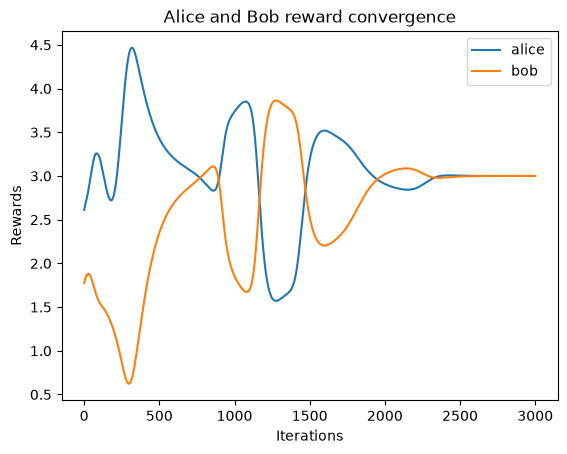

In [ ]:
plt.plot(alice_payoff_history[:3000],label = "alice")
plt.plot(bob_payoff_history[:3000],label = "bob")
#plt.axvline(alice_max_payoff_index)
#plt.axvline(bob_min_payoff_index)
plt.legend()
plt.xlabel("Iterations")
plt.ylabel("Rewards")
plt.title("Alice and Bob reward convergence")
plt.show()

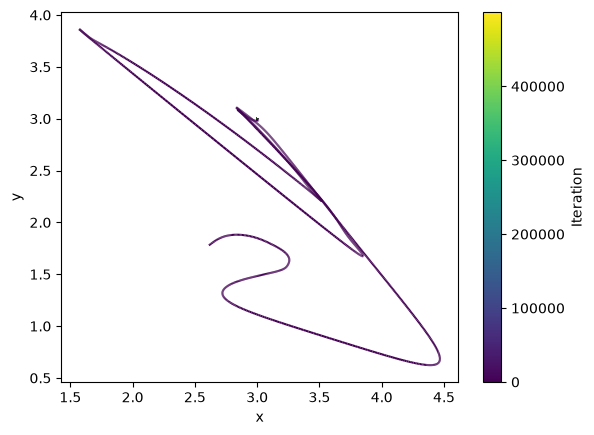

In [ ]:
points = np.array([alice_payoff_history,bob_payoff_history]).T .reshape(-1,1,2)
segments = np.concatenate([points[:-1],points[1:]],axis=1)
z = np.arange(len(alice_payoff_history))
lc = LineCollection(segments,cmap="viridis")
lc.set_array(z[:-1])

fig,ax= plt.subplots()

ax.add_collection(lc)
ax.autoscale()

cbar = fig.colorbar(lc,ax=ax)
cbar.set_label("Iteration")

ax.set_xlabel("x")
ax.set_ylabel("y")
plt.show()

In [ ]:

plt.figure(figsize=(7, 6))

plt.hist2d(
    alice_payoff_history,
    bob_payoff_history,
    bins=50000
)

plt.colorbar(label="Number of visits")

plt.xlabel("Alice Payoff")
plt.ylabel("Bob Payoff")

plt.xlim(0, 5)
plt.ylim(0, 5)

plt.title("RL Trajectory in Payoff Space")

plt.show()

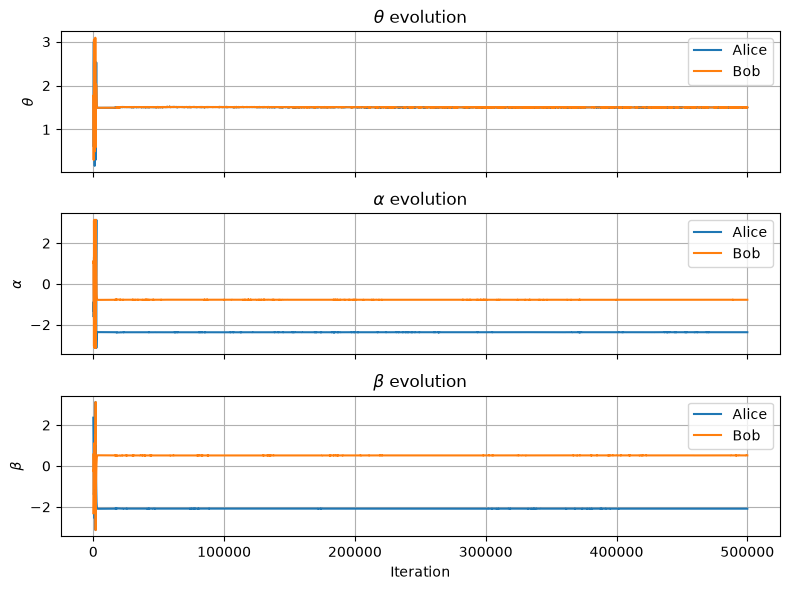

In [ ]:
fig, axes = plt.subplots(3, 1, figsize=(8, 6), sharex=True)

iterations_axis = np.arange(len(alice_strategy_history))

# φ1
axes[0].plot(
    iterations_axis,
    alice_strategy_history[:, 0],
    label="Alice"
)
axes[0].plot(
    iterations_axis,
    bob_strategy_history[:, 0],
    label="Bob"
)
axes[0].set_ylabel(r"$\theta$")
axes[0].set_title(r"$\theta$ evolution")
axes[0].legend()
axes[0].grid(True)

# φ2
axes[1].plot(
    iterations_axis,
    alice_strategy_history[:, 1],
    label="Alice"
)
axes[1].plot(
    iterations_axis,
    bob_strategy_history[:, 1],
    label="Bob"
)
axes[1].set_ylabel(r"$\alpha$")
axes[1].set_title(r"$\alpha$ evolution")
axes[1].legend()
axes[1].grid(True)

# φ3
axes[2].plot(
    iterations_axis,
    alice_strategy_history[:, 2],
    label="Alice"
)
axes[2].plot(
    iterations_axis,
    bob_strategy_history[:, 2],
    label="Bob"
)
axes[2].set_ylabel(r"$\beta$")
axes[2].set_xlabel("Iteration")
axes[2].set_title(r"$\beta$ evolution")
axes[2].legend()
axes[2].grid(True)

plt.tight_layout()
plt.show()

In [ ]:
C = pd.strategy([0.0,0.0,0.0])
D = pd.strategy([np.pi,0.0,0.0])

print("C,C =", pd.compute_payoffs(0.0, C, C, 1))
print("D,C =", pd.compute_payoffs(0.0, D, C, 1))
print("C,D =", pd.compute_payoffs(0.0, C, D, 1))
print("D,D =", pd.compute_payoffs(0.0, D, D, 1))

C,C = (3.0, 3.0)
D,C = (5.0, 1.1248198369963932e-32)
C,D = (1.1248198369963932e-32, 5.0)
D,D = (1.0, 1.0)


In [ ]:
@njit
def best_response_A(gamma, UA, UB, n_samples):

    best_payoff = -1.0
    best_U = UA.copy()

    for _ in range(n_samples):

        direction = np.random.normal(0.0, 1.0, 3)
        norm = np.sqrt(
            direction[0]**2 +
            direction[1]**2 +
            direction[2]**2
        )

        direction /= norm

        angle = np.random.uniform(-np.pi, np.pi)

        trial_U = UA @ pd.exp_su2(angle * direction)

        payoff_A, _ = pd.compute_payoffs(
            gamma,
            trial_U,
            UB,
            1
        )

        if payoff_A > best_payoff:
            best_payoff = payoff_A
            best_U = trial_U.copy()

    return best_payoff, best_U

print(best_response_A(gamma,final_A,final_B,100_000))

(4.999981253295101, array([[-0.33862757+0.59359309j,  0.51254044+0.51988548j],
       [-0.51254044+0.51988548j, -0.33862757-0.59359309j]]))


In [ ]:
best_A = -np.inf

for _ in range(1000000):

    direction = np.random.randn(3)
    direction /= np.linalg.norm(direction)

    angle = 2.0 * np.pi * np.random.rand()

    UA_test = UA @ pd.exp_su2(angle * direction)

    payoff_A, _ = pd.compute_payoffs(
        gamma,
        UA_test,
        UB,
        1
    )

    if payoff_A > best_A:
        best_A = payoff_A

print("Alice current payoff =", final_payoff_A)
print("Alice best deviation  =", best_A)

Alice current payoff = 2.999999993427894
Alice best deviation  = 4.999926725020093


In [ ]:
best_B = -np.inf

for _ in range(100000):

    direction = np.random.randn(3)
    direction /= np.linalg.norm(direction)

    angle = 2.0 * np.pi * np.random.rand()

    UB_test = UB @ pd.exp_su2(angle * direction)

    _, payoff_B = pd.compute_payoffs(
        gamma,
        UA,
        UB_test,
        1
    )

    if payoff_B > best_B:
        best_B = payoff_B

print("Bob current payoff =", final_payoff_B)
print("Bob best deviation  =", best_B)

Bob current payoff = 2.9999999934278865
Bob best deviation  = 4.996888118470812


In [ ]:
grad_A, grad_B = compute_riemannian_gradients(
    gamma,
    UA,
    UB,
    1e-6
)

print("grad_A =", grad_A)
print("grad_B =", grad_B)

print("||grad_A|| =", np.linalg.norm(grad_A))
print("||grad_B|| =", np.linalg.norm(grad_B))


test_lr = 1e-5

UA_test = UA @ pd.exp_su2(test_lr * grad_A)
UB_test = UB @ pd.exp_su2(test_lr * grad_B)

old_A, old_B = pd.compute_payoffs(gamma, UA, UB,1)
new_A, new_B = pd.compute_payoffs(gamma, UA_test, UB_test,1)

print("Old:", old_A, old_B)
print("New:", new_A, new_B)

grad_A = [-3.67832431e-05 -1.08292930e-04  9.75575176e-06]
grad_B = [-1.11493037e-04 -2.70272693e-05  3.78830300e-06]
||grad_A|| = 0.00011478475679910528
||grad_B|| = 0.0001147846759421231
Old: 2.999999993427894 2.9999999934278865
New: 2.999999993428157 2.9999999934281494
